# New Diffusion Attributes
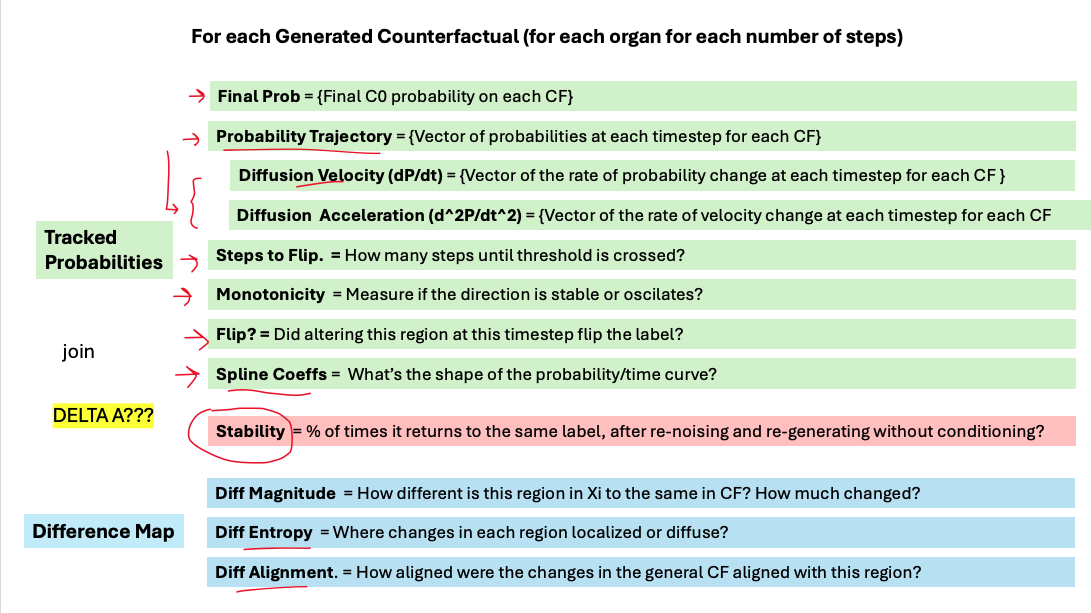

## Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import json
from PIL import Image
import os
from scipy.interpolate import splrep, splev
import seaborn as sns

In [2]:
import os
DATA_ROOT = os.environ.get("THESIS_DATA", "/work3/s251710/thesis_data")

# Loading the data
### From the new 4k samples (1k per quadrant) - 15CF each: General CF, Left Lung, Right Lung, Diaphragm, Spine for 3 t_step values

In [3]:
# Load Config json
config_json_path = '/zhome/d0/a/221493/thesis/results/diverse_cf/config.json'
with open(config_json_path, 'r') as f:
    config = json.load(f)
    
# Load Manifest
manifest_path = '/zhome/d0/a/221493/thesis/results/diverse_cf/cf_manifest.csv'
manifest = pd.read_csv(manifest_path)

In [4]:
config

{'t_start_values': [5, 10, 20],
 'guidance_weight': 0.05,
 'conditions': ['general',
  'Facies Diaphragmatica',
  'Left Lung',
  'Right Lung',
  'Spine'],
 'regions': ['Facies Diaphragmatica', 'Left Lung', 'Right Lung', 'Spine'],
 'control_region': 'Spine',
 'n_per_cell': 1000,
 'threshold': 0.5634,
 'seed': 42,
 'dilate_k': 9,
 'n_shards': 256,
 'anchor_level': 't-1',
 'noise_matching': 'shared_per_(image,t_start)',
 'source_csv': '/work3/s251710/thesis_results/C2_custom/effusion/c2_data.csv'}

In [5]:
manifest

,cf_id,path,patient_id,orig_prob,pred,true,correct,region,t_start,cf_tensor_path,cf_prob,flipped,mask_empty
0,train_patient00012_study2_view1_frontal__gener...,CheXpert-v1.0-small/train/patient00012/study2/...,patient00012,0.061508,0,0,1,general,5,/work3/s251710/thesis_results/diverse_cf/tenso...,0.900621,1,0
1,train_patient00012_study2_view1_frontal__Facie...,CheXpert-v1.0-small/train/patient00012/study2/...,patient00012,0.061508,0,0,1,Facies Diaphragmatica,5,/work3/s251710/thesis_results/diverse_cf/tenso...,0.873309,1,0
2,train_patient00012_study2_view1_frontal__Left-...,CheXpert-v1.0-small/train/patient00012/study2/...,patient00012,0.061508,0,0,1,Left Lung,5,/work3/s251710/thesis_results/diverse_cf/tenso...,0.161610,0,0
3,train_patient00012_study2_view1_frontal__Right...,CheXpert-v1.0-small/train/patient00012/study2/...,patient00012,0.061508,0,0,1,Right Lung,5,/work3/s251710/thesis_results/diverse_cf/tenso...,0.524806,0,0
4,train_patient00012_study2_view1_frontal__Spine...,CheXpert-v1.0-small/train/patient00012/study2/...,patient00012,0.061508,0,0,1,Spine,5,/work3/s251710/thesis_results/diverse_cf/tenso...,0.180576,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
81460,train_patient47314_study1_view1_frontal__gener...,CheXpert-v1.0-small/train/patient47314/study1/...,patient47314,0.007507,0,0,1,general,20,/work3/s251710/thesis_results/diverse_cf/tenso...,0.931152,1,0
81461,train_patient47314_study1_view1_frontal__Facie...,CheXpert-v1.0-small/train/patient47314/study1/...,patient47314,0.007507,0,0,1,Facies Diaphragmatica,20,/work3/s251710/thesis_results/diverse_cf/tenso...,0.907701,1,0
81462,train_patient47314_study1_view1_frontal__Left-...,CheXpert-v1.0-small/train/patient47314/study1/...,patient47314,0.007507,0,0,1,Left Lung,20,/work3/s251710/thesis_results/diverse_cf/tenso...,0.754693,1,0
81463,train_patient47314_study1_view1_frontal__Right...,CheXpert-v1.0-small/train/patient47314/study1/...,patient47314,0.007507,0,0,1,Right Lung,20,/work3/s251710/thesis_results/diverse_cf/tenso...,0.821449,1,0


In [6]:
# Count Of unique values in column "path"
manifest['path'].nunique()

# Each row has a "pred" and "true" column. We need to add to each, a column alled quadrant (tp,tn,fp,fn) based on the values of pred and true.
manifest['quadrant'] = manifest.apply(lambda row: 'tp' if row['pred'] == 1 and row['true'] == 1 else ('tn' if row['pred'] == 0 and row['true'] == 0 else ('fp' if row['pred'] == 1 and row['true'] == 0 else 'fn')), axis=1)

In [7]:
# coUNT TEH NUMBER OF UNIQUE "PATH" VALUES FOR EACH QUADRANT
quadrant_counts = manifest.groupby('quadrant')['path'].nunique()
quadrant_counts

quadrant
fn    1495
fp    1102
tn    1834
tp    1000
Name: path, dtype: int64

In [8]:
# Count the bumber of counterfactuals that each image ("path") has. So how many rows have the same "path" value
path_counts = manifest.groupby('path').size()

count = 0 
for path in path_counts.index:
    if path_counts[path] != 15:
        count += 1
        
if count == 0:
    print("All images have 15 counterfactuals ✅")

All images have 15 counterfactuals ✅


---

# Look at each sample's total  available information

In [9]:
# Pick a random image ("path"), from a quadrant
quadrant = 'fp'  # Change this to 'tp', 'tn', 'fp', or 'fn' to select a different quadrant
sample_path = np.random.choice(manifest[manifest['quadrant'] == quadrant]['path'].unique())
samples = manifest[manifest['path'] == sample_path]
print("Number of CF:", len(samples))
samples

Number of CF: 15


,cf_id,path,patient_id,orig_prob,pred,true,correct,region,t_start,cf_tensor_path,cf_prob,flipped,mask_empty,quadrant
61875,train_patient33753_study5_view1_frontal__gener...,CheXpert-v1.0-small/train/patient33753/study5/...,patient33753,0.996855,1,0,0,general,5,/work3/s251710/thesis_results/diverse_cf/tenso...,0.197490,1,0,fp
61876,train_patient33753_study5_view1_frontal__Facie...,CheXpert-v1.0-small/train/patient33753/study5/...,patient33753,0.996855,1,0,0,Facies Diaphragmatica,5,/work3/s251710/thesis_results/diverse_cf/tenso...,0.277980,1,0,fp
61877,train_patient33753_study5_view1_frontal__Left-...,CheXpert-v1.0-small/train/patient33753/study5/...,patient33753,0.996855,1,0,0,Left Lung,5,/work3/s251710/thesis_results/diverse_cf/tenso...,0.572807,0,0,fp
61878,train_patient33753_study5_view1_frontal__Right...,CheXpert-v1.0-small/train/patient33753/study5/...,patient33753,0.996855,1,0,0,Right Lung,5,/work3/s251710/thesis_results/diverse_cf/tenso...,0.992333,0,0,fp
61879,train_patient33753_study5_view1_frontal__Spine...,CheXpert-v1.0-small/train/patient33753/study5/...,patient33753,0.996855,1,0,0,Spine,5,/work3/s251710/thesis_results/diverse_cf/tenso...,0.977806,0,0,fp
61880,train_patient33753_study5_view1_frontal__gener...,CheXpert-v1.0-small/train/patient33753/study5/...,patient33753,0.996855,1,0,0,general,10,/work3/s251710/thesis_results/diverse_cf/tenso...,0.159570,1,0,fp
61881,train_patient33753_study5_view1_frontal__Facie...,CheXpert-v1.0-small/train/patient33753/study5/...,patient33753,0.996855,1,0,0,Facies Diaphragmatica,10,/work3/s251710/thesis_results/diverse_cf/tenso...,0.240174,1,0,fp
61882,train_patient33753_study5_view1_frontal__Left-...,CheXpert-v1.0-small/train/patient33753/study5/...,patient33753,0.996855,1,0,0,Left Lung,10,/work3/s251710/thesis_results/diverse_cf/tenso...,0.510326,1,0,fp
61883,train_patient33753_study5_view1_frontal__Right...,CheXpert-v1.0-small/train/patient33753/study5/...,patient33753,0.996855,1,0,0,Right Lung,10,/work3/s251710/thesis_results/diverse_cf/tenso...,0.991709,0,0,fp
61884,train_patient33753_study5_view1_frontal__Spine...,CheXpert-v1.0-small/train/patient33753/study5/...,patient33753,0.996855,1,0,0,Spine,10,/work3/s251710/thesis_results/diverse_cf/tenso...,0.959190,0,0,fp


In [10]:
# Load all CF tensors for this sample:
for i, row in samples.iterrows():
    cf_tensor_path = row['cf_tensor_path']
    cf_tensor = np.load(cf_tensor_path)
    print(f"CF {i}: shape: {cf_tensor.shape}, min: {cf_tensor.min()}, max: {cf_tensor.max()}")
    

CF 61875: shape: (224, 224), min: -1.0693359375, max: 1.033203125
CF 61876: shape: (224, 224), min: -1.0, max: 1.0478515625
CF 61877: shape: (224, 224), min: -1.0, max: 1.03515625
CF 61878: shape: (224, 224), min: -1.0, max: 1.0126953125
CF 61879: shape: (224, 224), min: -1.0, max: 1.0478515625
CF 61880: shape: (224, 224), min: -1.044921875, max: 1.0693359375
CF 61881: shape: (224, 224), min: -1.0, max: 1.0498046875
CF 61882: shape: (224, 224), min: -1.0, max: 1.02734375
CF 61883: shape: (224, 224), min: -1.0, max: 1.0
CF 61884: shape: (224, 224), min: -1.0, max: 1.0380859375
CF 61885: shape: (224, 224), min: -1.064453125, max: 1.0517578125
CF 61886: shape: (224, 224), min: -1.0, max: 1.0634765625
CF 61887: shape: (224, 224), min: -1.0, max: 1.0380859375
CF 61888: shape: (224, 224), min: -1.0, max: 1.0
CF 61889: shape: (224, 224), min: -1.0, max: 1.0546875


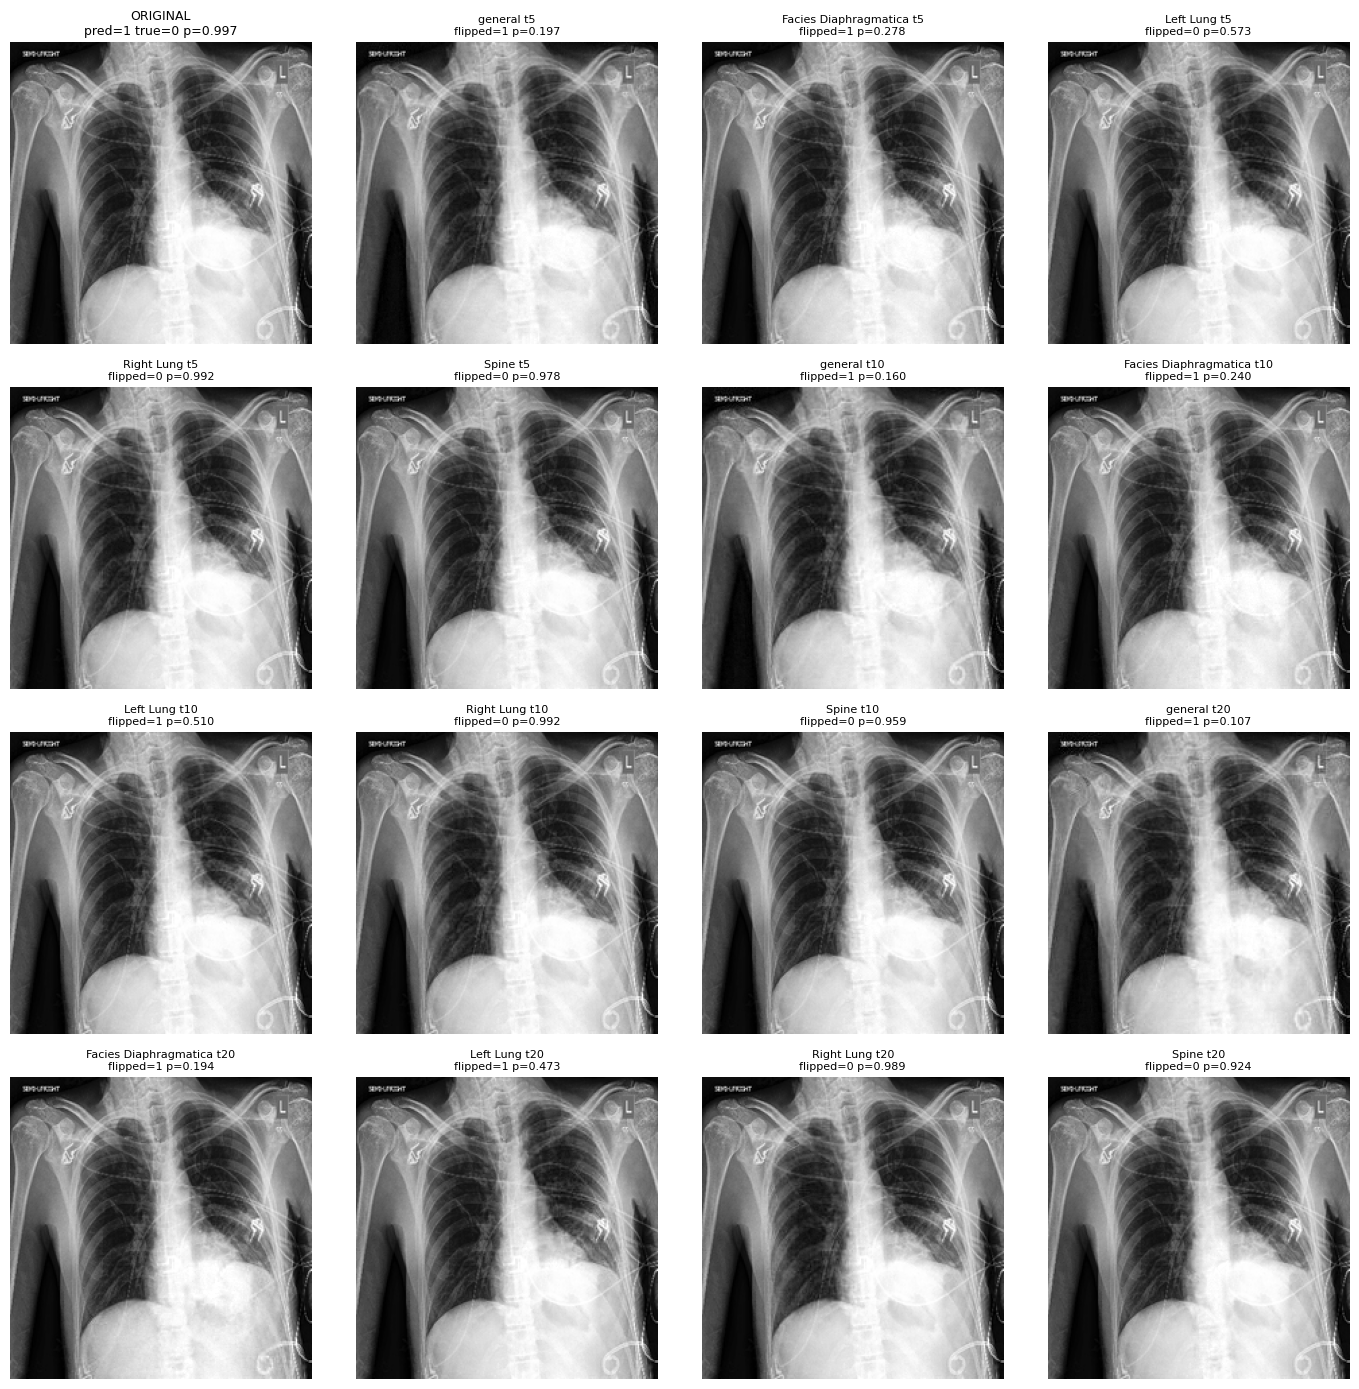

In [11]:

full_path = os.path.join(DATA_ROOT, samples.iloc[0]['path'])

# match the CF preprocessing so panels are comparable
orig = Image.open(full_path).convert('L').resize((224, 224), Image.LANCZOS)
orig = np.array(orig).astype(np.float32) / 255.0          # [0,1]

fig, axes = plt.subplots(4, 4, figsize=(14, 14))
axes = axes.ravel()

axes[0].imshow(orig, cmap='gray', vmin=0, vmax=1)
row0 = samples.iloc[0]
axes[0].set_title(f"ORIGINAL\npred={row0['pred']} true={row0['true']} "
                  f"p={row0['orig_prob']:.3f}", fontsize=9)
axes[0].axis('off')

for ax, (_, row) in zip(axes[1:], samples.iterrows()):
    ax.axis('off')
    if row['mask_empty'] == 1:
        ax.set_title(f"{row['region']} t{row['t_start']}\n(mask empty)", fontsize=8)
        continue
    cf = np.load(row['cf_tensor_path']).astype(np.float32)
    cf = (cf + 1) / 2                                      # [-1,1] -> [0,1]
    ax.imshow(cf, cmap='gray', vmin=0, vmax=1)
    ax.set_title(f"{row['region']} t{row['t_start']}\n"
                 f"flipped={row['flipped']} p={row['cf_prob']:.3f}", fontsize=8)

plt.tight_layout()



In [12]:
import hashlib, os

OUTPUT_DIR = '/zhome/d0/a/221493/thesis/results/diverse_cf'
N_SHARDS = 256

def traj_path(cf_id, output_dir=OUTPUT_DIR):
    h = int(hashlib.md5(cf_id.encode()).hexdigest(), 16)
    return os.path.join(output_dir, "trajectories", f"{h % N_SHARDS:03d}", f"{cf_id}.npy")

trajs = {}
for _, row in samples.iterrows():
    if row['mask_empty'] == 1:
        continue
    trajs[(row['region'], row['t_start'])] = np.load(traj_path(row['cf_id']))


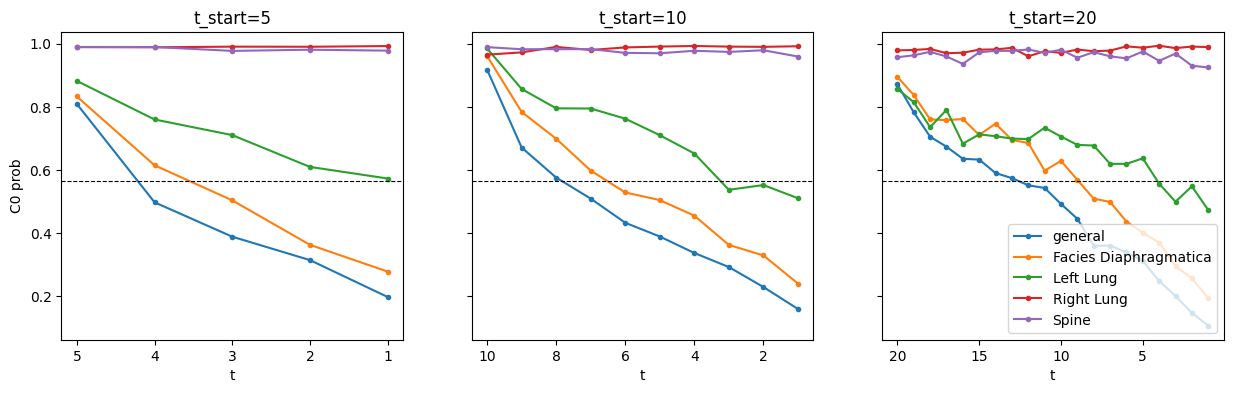

In [13]:
# CONVENTION (applies to every trajectory cell below):
# Trajectory files are stored in DENOISING ORDER already: t_vals run t_start -> 1,
# and traj[-1, 1] == cf_prob. So we NEVER reverse the array. Row i = step i+1.
# The t axis decreases as denoising proceeds, so we invert_xaxis() for display only.

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, t in zip(axes, sorted({t for _, t in trajs})):
    for (region, tt), traj in trajs.items():
        if tt != t:
            continue
        ax.plot(traj[:, 0], traj[:, 1], marker='o', ms=3, label=region)
    ax.invert_xaxis()                       # t counts down as denoising proceeds
    ax.axhline(config['threshold'], ls='--', c='k', lw=0.8)
    ax.set_title(f"t_start={t}"); ax.set_xlabel("t")
axes[0].set_ylabel("C0 prob");
axes[2].legend(fontsize=10, loc='lower right')


In [14]:
# Fit a b spline in the trajectories to extract the coefficients as scalars that represent the shape of the trajectory. 

POLY_DEG = 3

rows = []
for (region, t), traj in trajs.items():
    y = traj[:, 1]                        # already in denoising order
    n = len(y)

    # Normalize x to [0,1] so coefficients mean the same thing at t5/t10/t20.
    x = np.linspace(0, 1, n)
    c = np.polyfit(x, y, POLY_DEG)[::-1]  # -> ascending: [const, linear, quad, cubic]

    rows.append({
        'region': region, 't_start': t,
        'p0_level':     c[0],   # value at start of the descent
        'p1_slope':     c[1],   # overall rate of change
        'p2_curvature': c[2],   # decelerating (+) vs accelerating (-)
        'p3_sshape':    c[3],   # S-bend
        'resid':        np.sqrt(np.mean((y - np.polyval(c[::-1], x))**2)),
    })

poly_feats = pd.DataFrame(rows)
poly_feats.round(4)



,region,t_start,p0_level,p1_slope,p2_curvature,p3_sshape,resid
0,general,5,0.8077,-1.7506,2.4476,-1.3085,0.0048
1,Facies Diaphragmatica,5,0.8294,-0.9595,0.6744,-0.2695,0.0119
2,Left Lung,5,0.8785,-0.4688,0.2058,-0.0461,0.0128
3,Right Lung,5,0.9888,-0.0003,0.0036,0.0001,0.0005
4,Spine,5,0.9901,-0.0089,-0.0320,0.0293,0.0027
5,general,10,0.8953,-1.9262,2.5787,-1.3978,0.0172
6,Facies Diaphragmatica,10,0.9532,-1.5717,1.9047,-1.0492,0.0135
7,Left Lung,10,0.9563,-0.6428,0.4060,-0.2244,0.0298
8,Right Lung,10,0.9652,0.1007,-0.1329,0.0585,0.0034
9,Spine,10,0.9903,-0.0823,0.1593,-0.1033,0.0047


t5   general                resid=0.00483
t5   Facies Diaphragmatica  resid=0.01189
t5   Left Lung              resid=0.01276
t5   Right Lung             resid=0.00052
t5   Spine                  resid=0.00270
t10  general                resid=0.01719
t10  Facies Diaphragmatica  resid=0.01355
t10  Left Lung              resid=0.02976
t10  Right Lung             resid=0.00336
t10  Spine                  resid=0.00468
t20  general                resid=0.02180
t20  Facies Diaphragmatica  resid=0.02244
t20  Left Lung              resid=0.02820
t20  Right Lung             resid=0.00624
t20  Spine                  resid=0.01159


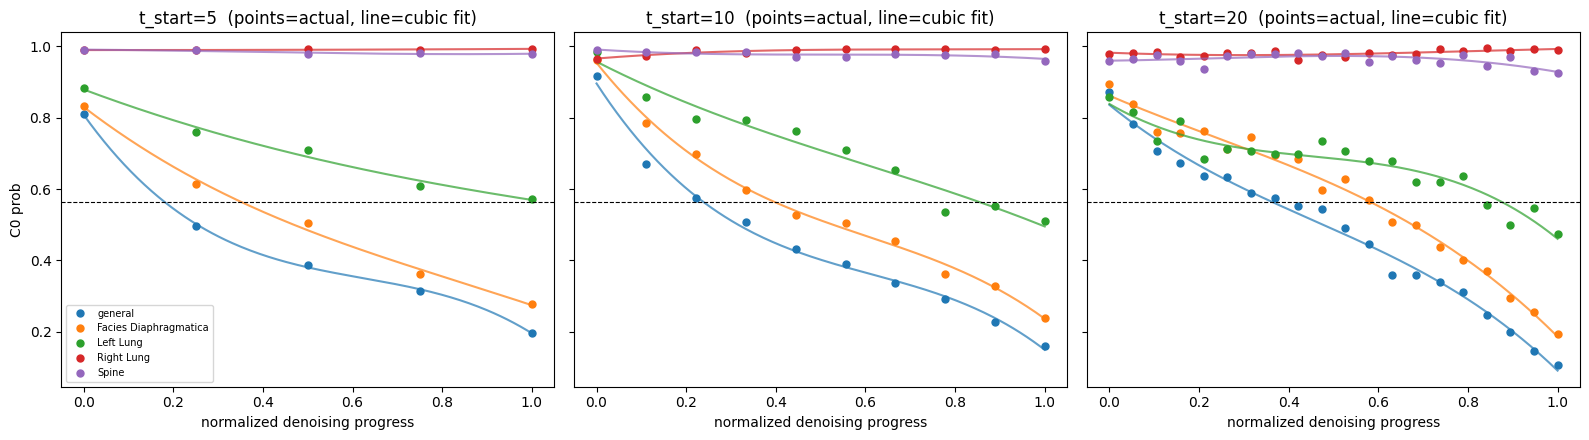

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)

for ax, t in zip(axes, sorted({tt for _, tt in trajs})):
    for i, ((region, tt), traj) in enumerate(
            (k, v) for k, v in trajs.items() if k[1] == t):
        y = traj[:, 1]
        n = len(y)
        x = np.linspace(0, 1, n)
        c = np.polyfit(x, y, POLY_DEG)

        colour = f"C{i}"
        # actual trajectory: markers only
        ax.plot(x, y, 'o', ms=5, color=colour, label=region)
        # fitted polynomial: smooth line, same colour
        xs = np.linspace(0, 1, 200)
        ax.plot(xs, np.polyval(c, xs), '-', lw=1.5, color=colour, alpha=0.7)

        resid = np.sqrt(np.mean((y - np.polyval(c, x))**2))
        print(f"t{t:<3} {region:<22} resid={resid:.5f}")

    ax.axhline(config['threshold'], ls='--', c='k', lw=0.8)
    ax.set_title(f"t_start={t}  (points=actual, line=cubic fit)")
    ax.set_xlabel("normalized denoising progress")

axes[0].set_ylabel("C0 prob")
axes[0].legend(fontsize=7)
plt.tight_layout()


In [16]:
# Velocity = change in prob PER DENOISING STEP.
# No reversal (see convention above). We differentiate w.r.t. step index, not t_val:
# t_val decreases by 1 each step, so dividing by dt=-1 would flip the sign and make
# velocity disagree with the polynomial slope in the cell above. Step index is also
# what makes t5/t10/t20 comparable.
velocities = {}
for (region, t), traj in trajs.items():
    velocity = np.diff(traj[:, 1])         # prob change per step
    velocities[(region, t)] = velocity
    print(f"{region:<22} t{t:<3} velocity {velocity.shape} "
          f"v: {velocity[0]:+.3f} -> {velocity[-1]:+.3f}")


general                t5   velocity (4,) v: -0.312 -> -0.117
Facies Diaphragmatica  t5   velocity (4,) v: -0.218 -> -0.085
Left Lung              t5   velocity (4,) v: -0.122 -> -0.037
Right Lung             t5   velocity (4,) v: -0.001 -> +0.002
Spine                  t5   velocity (4,) v: -0.000 -> -0.003
general                t10  velocity (9,) v: -0.247 -> -0.070
Facies Diaphragmatica  t10  velocity (9,) v: -0.177 -> -0.089
Left Lung              t10  velocity (9,) v: -0.128 -> -0.042
Right Lung             t10  velocity (9,) v: +0.007 -> +0.002
Spine                  t10  velocity (9,) v: -0.007 -> -0.020
general                t20  velocity (19,) v: -0.089 -> -0.041
Facies Diaphragmatica  t20  velocity (19,) v: -0.057 -> -0.063
Left Lung              t20  velocity (19,) v: -0.042 -> -0.075
Right Lung             t20  velocity (19,) v: +0.001 -> -0.002
Spine                  t20  velocity (19,) v: +0.006 -> -0.006


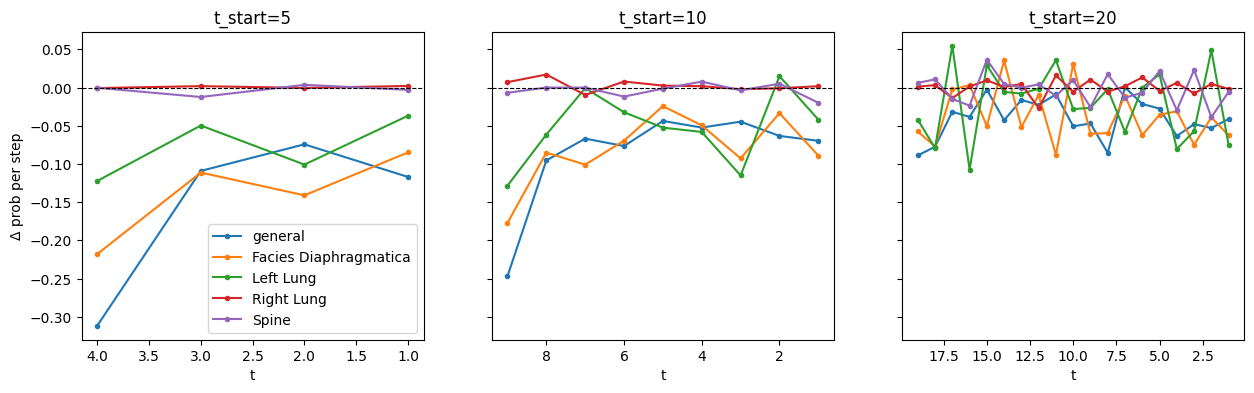

In [17]:
# Plot velocity — reuse the stored `velocities`, don't recompute (that's how the
# earlier version drifted out of sync with the cell above).
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, t in zip(axes, sorted({t for _, t in velocities})):
    for (region, tt), v in velocities.items():
        if tt != t:
            continue
        ax.plot(trajs[(region, tt)][1:, 0], v, marker='o', ms=3, label=region)
    ax.invert_xaxis()
    ax.axhline(0, ls='--', c='k', lw=0.8)
    ax.set_title(f"t_start={t}"); ax.set_xlabel("t")
axes[0].set_ylabel("Δ prob per step"); axes[0].legend(fontsize=10)


In [18]:
# Acceleration = change in velocity per step. Derived from the stored `velocities`
# so it can never disagree with them (the old version recomputed and divided by dt).
accelerations = {}
for (region, t), v in velocities.items():
    acceleration = np.diff(v)
    accelerations[(region, t)] = acceleration
    print(f"{region:<22} t{t:<3} acceleration {acceleration.shape} "
          f"a: {acceleration[0]:+.3f} -> {acceleration[-1]:+.3f}")


general                t5   acceleration (3,) a: +0.203 -> -0.043
Facies Diaphragmatica  t5   acceleration (3,) a: +0.107 -> +0.056
Left Lung              t5   acceleration (3,) a: +0.073 -> +0.064
Right Lung             t5   acceleration (3,) a: +0.003 -> +0.003
Spine                  t5   acceleration (3,) a: -0.012 -> -0.007
general                t10  acceleration (8,) a: +0.151 -> -0.006
Facies Diaphragmatica  t10  acceleration (8,) a: +0.092 -> -0.056
Left Lung              t10  acceleration (8,) a: +0.067 -> -0.057
Right Lung             t10  acceleration (8,) a: +0.010 -> +0.003
Spine                  t10  acceleration (8,) a: +0.007 -> -0.025
general                t20  acceleration (18,) a: +0.011 -> +0.012
Facies Diaphragmatica  t20  acceleration (18,) a: -0.020 -> -0.024
Left Lung              t20  acceleration (18,) a: -0.037 -> -0.124
Right Lung             t20  acceleration (18,) a: +0.002 -> -0.007
Spine                  t20  acceleration (18,) a: +0.005 -> +0.033


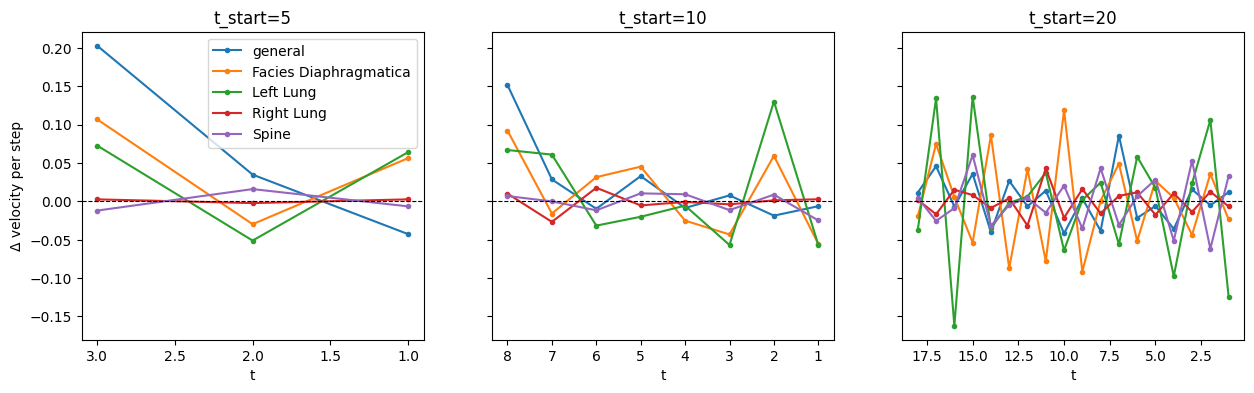

In [19]:
# Plot acceleration — reuse the stored `accelerations`.
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, t in zip(axes, sorted({t for _, t in accelerations})):
    for (region, tt), a in accelerations.items():
        if tt != t:
            continue
        ax.plot(trajs[(region, tt)][2:, 0], a, marker='o', ms=3, label=region)
    ax.invert_xaxis()
    ax.axhline(0, ls='--', c='k', lw=0.8)
    ax.set_title(f"t_start={t}"); ax.set_xlabel("t")
axes[0].set_ylabel("Δ velocity per step"); axes[0].legend(fontsize=10)


In [20]:
# Print flipped vector (a vector with the value of teh "flipped" column for each CF)
flipped_vector = samples['flipped'].values
flipped_vector

array([1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0])

In [21]:
# Count number of steps to flip for each CF (the first index where the prob crosses the threshold)

THR = config['threshold']

for _, row in samples.iterrows():
    if row['mask_empty'] == 1:
        continue
    p = row['cf_tensor_path'].replace('/tensors/', '/trajectories/')
    traj = np.load(p)                      # rows: t_start ... 1, i.e. already in step order
    probs = traj[:, 1]
    pred = bool(int(row['pred']))
    crossed = (probs >= THR) != pred
    steps = int(np.argmax(crossed)) + 1 if crossed.any() else None
    print(f"{row['region']:<22} t{row['t_start']:<3} "
          f"orig={row['orig_prob']:.3f} -> step1={probs[0]:.3f} -> final={probs[-1]:.3f}  "
          f"steps={steps}")


general                t5   orig=0.997 -> step1=0.809 -> final=0.197  steps=2
Facies Diaphragmatica  t5   orig=0.997 -> step1=0.833 -> final=0.278  steps=3
Left Lung              t5   orig=0.997 -> step1=0.882 -> final=0.573  steps=None
Right Lung             t5   orig=0.997 -> step1=0.989 -> final=0.992  steps=None
Spine                  t5   orig=0.997 -> step1=0.989 -> final=0.978  steps=None
general                t10  orig=0.997 -> step1=0.918 -> final=0.160  steps=4
Facies Diaphragmatica  t10  orig=0.997 -> step1=0.961 -> final=0.240  steps=5
Left Lung              t10  orig=0.997 -> step1=0.985 -> final=0.510  steps=8
Right Lung             t10  orig=0.997 -> step1=0.965 -> final=0.992  steps=None
Spine                  t10  orig=0.997 -> step1=0.989 -> final=0.959  steps=None
general                t20  orig=0.997 -> step1=0.871 -> final=0.107  steps=9
Facies Diaphragmatica  t20  orig=0.997 -> step1=0.894 -> final=0.194  steps=13
Left Lung              t20  orig=0.997 -> step1=

In [22]:
# Monotonicity check: for each CF, check if the prob is monotonically increasing or decreasing (depending on the pred value)
for _, row in samples.iterrows():
    if row['mask_empty'] == 1:
        continue
    p = row['cf_tensor_path'].replace('/tensors/', '/trajectories/')
    traj = np.load(p)                      # rows: t_start ... 1, i.e. already in step order
    probs = traj[:, 1]
    pred = bool(int(row['pred']))
    if pred:
        monotonic = np.all(np.diff(probs) <= 0)   # should be decreasing
    else:
        monotonic = np.all(np.diff(probs) >= 0)   # should be increasing
    print(f"{row['region']:<22} t{row['t_start']:<3} "
          f"orig={row['orig_prob']:.3f} -> step1={probs[0]:.3f} -> final={probs[-1]:.3f}  "
          f"monotonic={monotonic}")
    

general                t5   orig=0.997 -> step1=0.809 -> final=0.197  monotonic=True
Facies Diaphragmatica  t5   orig=0.997 -> step1=0.833 -> final=0.278  monotonic=True
Left Lung              t5   orig=0.997 -> step1=0.882 -> final=0.573  monotonic=True
Right Lung             t5   orig=0.997 -> step1=0.989 -> final=0.992  monotonic=False
Spine                  t5   orig=0.997 -> step1=0.989 -> final=0.978  monotonic=False
general                t10  orig=0.997 -> step1=0.918 -> final=0.160  monotonic=True
Facies Diaphragmatica  t10  orig=0.997 -> step1=0.961 -> final=0.240  monotonic=True
Left Lung              t10  orig=0.997 -> step1=0.985 -> final=0.510  monotonic=False
Right Lung             t10  orig=0.997 -> step1=0.965 -> final=0.992  monotonic=False
Spine                  t10  orig=0.997 -> step1=0.989 -> final=0.959  monotonic=False
general                t20  orig=0.997 -> step1=0.871 -> final=0.107  monotonic=False
Facies Diaphragmatica  t20  orig=0.997 -> step1=0.894 -> fi

In [23]:
def monotonicity_metrics(probs, pred):
    d = np.diff(probs)
    sign = -1.0 if pred else 1.0          # intended direction of travel
    d_signed = d * sign                   # positive = productive
    total = np.abs(d).sum() # total amount of change in the trajectory, abs for both directions, "how much it walked"
    ratio = d_signed[d_signed > 0].sum() / total if total > 0 else np.nan # it's the fraction of the total change that is in the intended direction
    backtrack = np.abs(d_signed[d_signed < 0]).sum() # total amount of change that is in the opposite direction
    n_rev = int((np.diff(np.sign(d)) != 0).sum()) # number of times the trajectory reverses direction
    net = probs[-1] - probs[0] # net change from start to finish
    tv = total / abs(net) if abs(net) > 1e-6 else np.nan # total variation ratio: how much the trajectory wobbles relative to the net change. 1 would be a straight line, 2 would be a zig-zag, etc.

    from scipy.stats import spearmanr
    rho = spearmanr(np.arange(len(probs)), probs).correlation * sign # spearman correlation of the trajectory with a straight line in the intended direction

    return dict(mono_ratio=ratio, backtrack=backtrack, n_reversals=n_rev,
                tv_ratio=tv, spearman=rho, net_delta=net * sign)

monotonicity_metrics(probs, pred)

{'mono_ratio': 0.55351216,
 'backtrack': 0.13534987,
 'n_reversals': 13,
 'tv_ratio': 9.343676,
 'spearman': 0.3037593984962406,
 'net_delta': 0.03244370222091675}

## Difference Maps (Xi - Cf)

In [24]:
# For each CF of our sample, calculate its difference map (Xi - Cf) and plot it alongside the original and CF images
# Original, preprocessed exactly as cf_generation.load_image does: grayscale,
# LANCZOS to 224, [0,1]. CF tensors are stored in [-1,1], so map them to [0,1] too.


def load_original(rel_path):
    """Original at CF preprocessing: grayscale, LANCZOS 224, [0,1]."""
    full = os.path.join(DATA_ROOT, rel_path)
    arr = np.array(Image.open(full).convert('L').resize((224, 224), Image.LANCZOS))
    return arr.astype(np.float32) / 255.0

orig = load_original(samples.iloc[0]['path'])

# (region, t_start) -> {'cf': ..., 'diff': ...}, same keying as trajs
diffs = {}
for _, row in samples.iterrows():
    if row['mask_empty'] == 1:
        continue
    cf = (np.load(row['cf_tensor_path']).astype(np.float32) + 1) / 2   # [-1,1] -> [0,1]
    diffs[(row['region'], row['t_start'])] = {'cf': cf, 'diff': orig - cf}



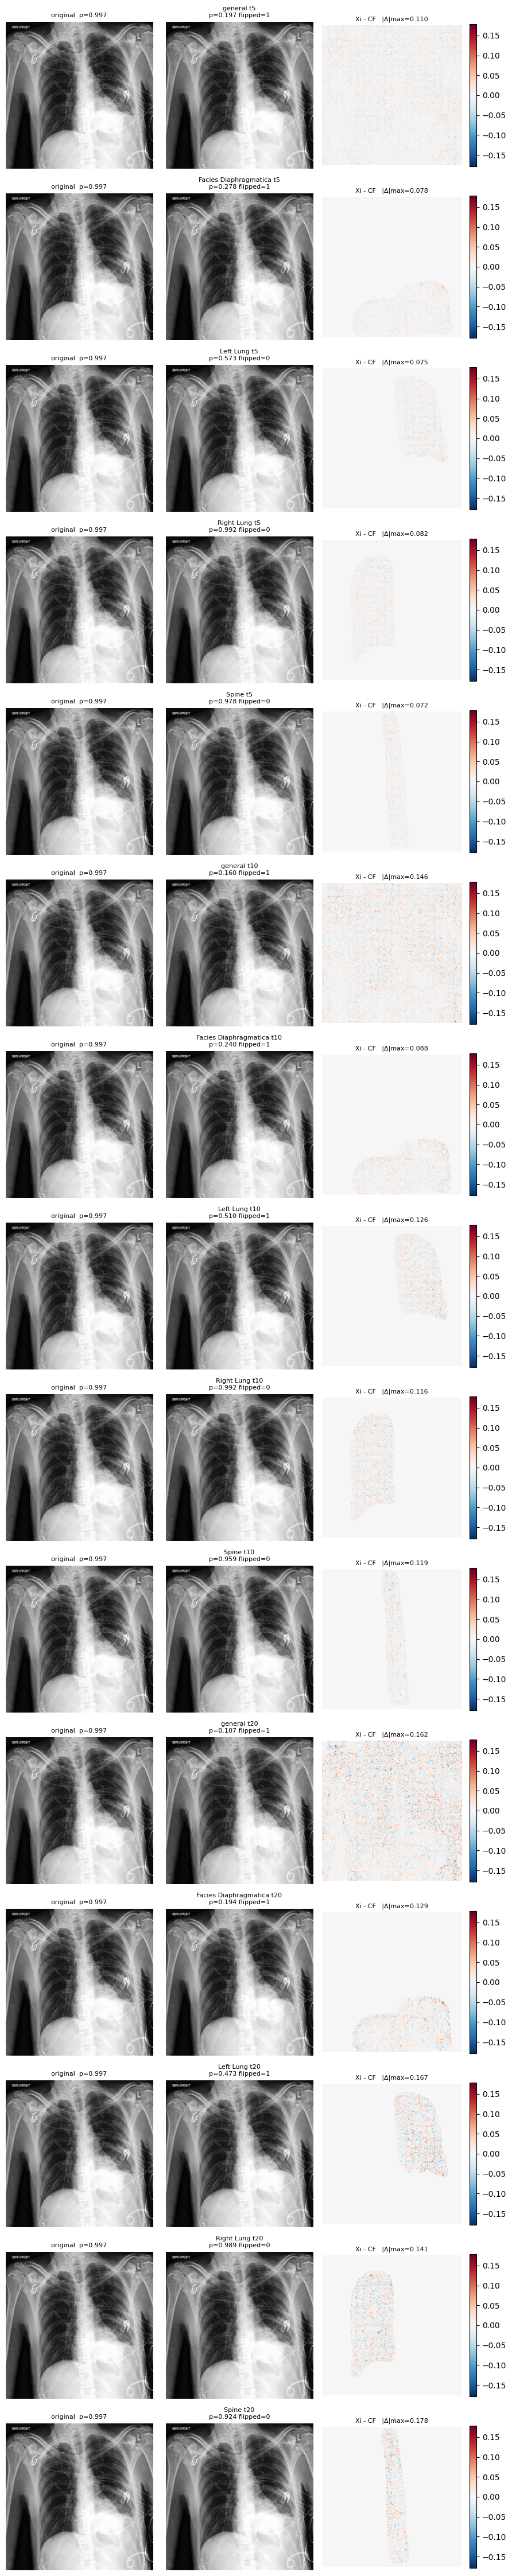

In [25]:
# one global limit so rows are comparable to each other
lim = max(np.abs(d['diff']).max() for d in diffs.values())

fig, axes = plt.subplots(len(diffs), 3, figsize=(9, 3 * len(diffs)))

for ax_row, ((region, t), d) in zip(axes, diffs.items()):
    row = samples[(samples['region'] == region) & (samples['t_start'] == t)].iloc[0]

    ax_row[0].imshow(orig, cmap='gray', vmin=0, vmax=1)
    ax_row[0].set_title(f"original  p={row['orig_prob']:.3f}", fontsize=8)

    ax_row[1].imshow(d['cf'], cmap='gray', vmin=0, vmax=1)
    ax_row[1].set_title(f"{region} t{t}\np={row['cf_prob']:.3f} "
                        f"flipped={row['flipped']}", fontsize=8)

    im = ax_row[2].imshow(d['diff'], cmap='RdBu_r', vmin=-lim, vmax=lim)
    ax_row[2].set_title(f"Xi - CF   |Δ|max={np.abs(d['diff']).max():.3f}", fontsize=8)
    plt.colorbar(im, ax=ax_row[2], fraction=0.046)

    for ax in ax_row:
        ax.axis('off')

plt.tight_layout()


In [26]:
# Calculate difference magnitude (L2 norm) of each difference map and print it alongside the original and CF probabilities
EDIT_EPS = 1e-4          # Minimum ammount of diff to consider a pixel "changed" (for entropy calculation)

def diff_features(dm, eps=EDIT_EPS):
    """Magnitude + spatial entropy over the pixels the CF actually changed."""
    
    a = np.abs(dm)
    m = a > eps
    n = int(m.sum())
    if n == 0:
        return dict(l1=0.0, l2=0.0, linf=0.0, mean_abs=0.0,
                    ent=np.nan, ent_norm=np.nan, area=0, frac_frame=0.0)

    vals = dm[m]
    av = a[m]
    s = av.sum()
    p = av / s
    ent = -(p * np.log2(p)).sum()

    return dict(
        l1=s, # total ammount of change, summed over every pixel
        l2=np.sqrt((vals**2).sum()), # suare root of summed squared change over every pixel. rewards concentrated change more than spread-out change
        peak_pixel=av.max(), # maximum change in any pixel
        mean_pixel_abs=av.mean(), # average change per changed pixel
        entropy=ent, # spatial entropy of the change, over the pixels that changed, measures the spread across the image. 0 = all change in one pixel, 1 = uniform change across all changed pixels
        ent_normalized_by_size=ent / np.log2(n) if n > 1 else np.nan, 
        area=n, # how many pixels changed
        frac_frame=n / dm.size, # fraction of the frame that changed
    )

feat = pd.DataFrame({k: diff_features(d['diff']) for k, d in diffs.items()}).T
feat.index = pd.MultiIndex.from_tuples(feat.index, names=['region', 't_start'])
feat.round(4)



,,l1,l2,peak_pixel,mean_pixel_abs,entropy,ent_normalized_by_size,area,frac_frame
region,t_start,,,,,,,,
general,5,651.7081,3.7531,0.1101,0.0131,15.1632,0.9715,49926.0,0.9950
Facies Diaphragmatica,5,120.9956,1.4825,0.0777,0.0086,13.0024,0.9436,14057.0,0.2802
Left Lung,5,130.5167,1.7485,0.0754,0.0101,12.7228,0.9315,12930.0,0.2577
Right Lung,5,142.9220,1.7942,0.0821,0.0102,12.9015,0.9366,14023.0,0.2795
Spine,5,78.2359,1.2559,0.0725,0.0076,12.2232,0.9173,10258.0,0.2044
general,10,848.4632,4.9487,0.1463,0.0170,15.1417,0.9701,49980.0,0.9961
Facies Diaphragmatica,10,151.7946,1.8808,0.0875,0.0108,12.9797,0.9418,14084.0,0.2807
Left Lung,10,177.5184,2.3808,0.1262,0.0137,12.7181,0.9311,12932.0,0.2577
Right Lung,10,191.6672,2.4228,0.1161,0.0136,12.8874,0.9353,14051.0,0.2800


In [27]:
EDIT_EPS = 1e-4

# Recover each region's mask from its own masked-CF diff map.
# Use any t_start — they agreed to within 0.1% — or OR them for robustness.
masks = {}
for r in config['regions']:
    ms = [np.abs(diffs[(r, t)]['diff']) > EDIT_EPS
          for t in sorted({tt for rr, tt in diffs if rr == r})]
    masks[r] = np.logical_or.reduce(ms)

gen_rows = []
for t in sorted({tt for _, tt in diffs}):
    a = np.abs(diffs[('general', t)]['diff'])
    total = a.sum()
    for r, m in masks.items():
        gen_rows.append({
            't_start': t, 'region': r,
            'share': a[m].sum() / total, # how much of the editing in the. general non-masked CF is attributable to this region
            'density': a[m].mean() / a.mean(), # how much more concentrated the editing is in this region than in the general non-masked CF
            'area_frac': m.mean(), # what fraction of the general non-masked CF is attributed to this region
        })
alloc = pd.DataFrame(gen_rows)
print(alloc.pivot_table(index='region', columns='t_start',
                        values=['share', 'density']).round(3))


                      density                share              
t_start                    5      10     20     5      10     20
region                                                          
Facies Diaphragmatica   0.856  0.812  0.780  0.241  0.229  0.220
Left Lung               1.054  1.054  1.048  0.272  0.272  0.271
Right Lung              1.033  1.035  1.026  0.290  0.290  0.288
Spine                   0.943  0.922  0.909  0.193  0.189  0.186


---

# Master feature table

One row per (Xi, CF) pair — i.e. per `(path, region, t_start)`. Every feature above,
as scalars, so it can go straight into a model or a correlation screen.

Velocity and acceleration are vectors of varying length (4/9/19 and 3/8/18 for
t5/t10/t20), so they are summarised by mean / max / min / std / argmax-position.
`argmax` is normalised to [0,1] so it means "how far into the descent the steepest
change happened", comparably across noise levels.

In [28]:
from scipy.stats import spearmanr

THR      = config['threshold']
POLY_DEG = 3
EDIT_EPS = 1e-4


def vec_summary(v, prefix):
    """Scalarise a variable-length derivative vector."""
    if len(v) == 0:
        return {f'{prefix}_{k}': np.nan
                for k in ('mean', 'max', 'min', 'std', 'absmax', 'argmax_pos')}
    return {
        f'{prefix}_mean':       float(v.mean()),
        f'{prefix}_max':        float(v.max()),
        f'{prefix}_min':        float(v.min()),
        f'{prefix}_std':        float(v.std()),
        f'{prefix}_absmax':     float(np.abs(v).max()),
        # where the biggest move happened, as a fraction of the descent
        f'{prefix}_argmax_pos': float(np.argmax(np.abs(v)) / max(len(v) - 1, 1)),
    }


def traj_features(probs, pred):
    """
    All trajectory-derived scalars. `probs` is in DENOISING ORDER (never reversed).

    Flip bookkeeping — three distinct things, because a trajectory can cross the
    threshold and come back:
      first_cross_step : first step landing on the far side (NaN if never)
      ever_crossed     : did it EVER cross, even transiently
      steps_to_flip    : first_cross_step but ONLY for CFs that end flipped, i.e.
                         the step from which the crossing held. This is the one
                         that matches the manifest's `flipped` column.
    """
    sign = -1.0 if pred else 1.0          # intended direction of travel
    d    = np.diff(probs)                 # velocity, per step
    a    = np.diff(d)                     # acceleration, per step
    ds   = d * sign                       # positive = productive
    tot  = np.abs(d).sum()
    net  = probs[-1] - probs[0]

    crossed     = (probs >= THR) != bool(pred)
    first_cross = int(np.argmax(crossed)) + 1 if crossed.any() else np.nan
    ends_flipped = bool(crossed[-1])
    # step from which the flip held to the end
    if ends_flipped:
        held = len(crossed) - int(np.argmin(crossed[::-1]))
        steps_to_flip = held if not crossed.all() else 1
    else:
        steps_to_flip = np.nan

    # cubic shape descriptor on x normalised to [0,1]
    x = np.linspace(0, 1, len(probs))
    c = np.polyfit(x, probs, POLY_DEG)                    # highest-degree first
    resid = float(np.sqrt(np.mean((probs - np.polyval(c, x)) ** 2)))

    out = {
        'traj_start': float(probs[0]), 'traj_end': float(probs[-1]),
        'first_cross_step': first_cross,
        'ever_crossed': int(crossed.any()),
        'steps_to_flip': steps_to_flip,
        'ends_flipped': int(ends_flipped),
        'n_crossings': int((np.diff(crossed.astype(int)) != 0).sum()),
        # monotonicity
        'mono_ratio':  float(ds[ds > 0].sum() / tot) if tot > 0 else np.nan,
        'backtrack':   float(np.abs(ds[ds < 0]).sum()),
        'n_reversals': int((np.diff(np.sign(d)) != 0).sum()),
        # n_reversals scales with length -> also give a length-normalised rate
        'reversal_rate': float((np.diff(np.sign(d)) != 0).sum() / max(len(d) - 1, 1)),
        # tv_ratio blows up when net ~ 0, so gate it well above the noise floor
        'tv_ratio':    float(tot / abs(net)) if abs(net) > 0.02 else np.nan,
        'spearman':    float(spearmanr(np.arange(len(probs)), probs).correlation * sign),
        'net_delta':   float(net * sign),
        'total_variation': float(tot),
        # polynomial shape (ascending: const, linear, quad, cubic)
        'p0_level': float(c[3]), 'p1_slope': float(c[2]),
        'p2_curvature': float(c[1]), 'p3_sshape': float(c[0]),
        'poly_resid': resid,
    }
    out.update(vec_summary(d, 'vel'))
    out.update(vec_summary(a, 'acc'))
    return out


def diff_map_features(dm, eps=EDIT_EPS):
    """Magnitude + spatial entropy over the pixels the CF actually changed."""
    av = np.abs(dm)
    m  = av > eps
    n  = int(m.sum())
    if n == 0:
        return dict(l1=0.0, l2=0.0, peak_pixel=0.0, mean_pixel_abs=0.0,
                    entropy=np.nan, ent_normalized_by_size=np.nan,
                    area=0, frac_frame=0.0)
    vals, a = dm[m], av[m]
    s = a.sum()
    p = a / s
    ent = float(-(p * np.log2(p)).sum())
    return dict(
        l1=float(s),
        l2=float(np.sqrt((vals ** 2).sum())),
        peak_pixel=float(a.max()),
        mean_pixel_abs=float(a.mean()),
        entropy=ent,
        ent_normalized_by_size=ent / np.log2(n) if n > 1 else np.nan,
        area=n,
        frac_frame=n / dm.size,
    )


In [30]:
def build_image_features(img_rows, load_tensors=True):
    """
    All features for ONE image's 15 CFs -> list of dicts (one per (Xi, CF) pair).

    img_rows : the manifest rows for a single `path`.
    Alignment features (share/density) need the general CF plus the four masked
    diff maps, so they are computed per image and broadcast onto the general rows.
    """
    orig = load_original(img_rows.iloc[0]['path']) if load_tensors else None
    dmaps, recs = {}, []

    for _, row in img_rows.iterrows():
        rec = {
            'path': row['path'], 'cf_id': row['cf_id'],
            'patient_id': row['patient_id'],
            'region': row['region'], 't_start': int(row['t_start']),
            'orig_prob': row['orig_prob'], 'cf_prob': row['cf_prob'],
            'pred': int(row['pred']), 'true': int(row['true']),
            'correct': int(row['correct']), 'quadrant': row['quadrant'],
            'flipped': int(row['flipped']), 'mask_empty': int(row['mask_empty']),
            # distance from the decision boundary — the confounder to control for
            'boundary_dist': abs(row['orig_prob'] - THR),
        }

        if row['mask_empty'] == 1:
            recs.append(rec)
            continue

        probs = np.load(traj_path(row['cf_id']))[:, 1]     # denoising order
        rec.update(traj_features(probs, int(row['pred'])))

        if load_tensors:
            cf = (np.load(row['cf_tensor_path']).astype(np.float32) + 1) / 2
            dm = orig - cf
            dmaps[(row['region'], rec['t_start'])] = dm
            rec.update(diff_map_features(dm))

        recs.append(rec)

    # ── alignment: where did the UNMASKED CF spend its edit, per region? ──
    if load_tensors and dmaps:
        masks = {}
        for r in config['regions']:
            ms = [np.abs(dm) > EDIT_EPS for (rr, _), dm in dmaps.items() if rr == r]
            if ms:
                masks[r] = np.logical_or.reduce(ms)

        for rec in recs:
            if rec['region'] != 'general' or (('general', rec['t_start']) not in dmaps):
                continue
            a = np.abs(dmaps[('general', rec['t_start'])])
            tot, amean = a.sum(), a.mean()
            for r, m in masks.items():
                tag = r.replace(' ', '_')
                rec[f'align_share_{tag}']   = float(a[m].sum() / tot)
                rec[f'align_density_{tag}'] = float(a[m].mean() / amean)

    return recs


# Build for the current sample image
rows = build_image_features(samples)
cf_features = pd.DataFrame(rows)
print(cf_features.shape)
cf_features.head(15)

(15, 62)


,path,cf_id,patient_id,region,t_start,orig_prob,cf_prob,pred,true,correct,...,area,frac_frame,align_share_Facies_Diaphragmatica,align_density_Facies_Diaphragmatica,align_share_Left_Lung,align_density_Left_Lung,align_share_Right_Lung,align_density_Right_Lung,align_share_Spine,align_density_Spine
0,CheXpert-v1.0-small/train/patient33753/study5/...,train_patient33753_study5_view1_frontal__gener...,patient33753,general,5,0.996855,0.197490,1,0,0,...,49926,0.995018,0.241069,0.856163,0.272248,1.053873,0.289819,1.032808,0.193461,0.943078
1,CheXpert-v1.0-small/train/patient33753/study5/...,train_patient33753_study5_view1_frontal__Facie...,patient33753,Facies Diaphragmatica,5,0.996855,0.277980,1,0,0,...,14057,0.280154,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,CheXpert-v1.0-small/train/patient33753/study5/...,train_patient33753_study5_view1_frontal__Left-...,patient33753,Left Lung,5,0.996855,0.572807,1,0,0,...,12930,0.257693,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,CheXpert-v1.0-small/train/patient33753/study5/...,train_patient33753_study5_view1_frontal__Right...,patient33753,Right Lung,5,0.996855,0.992333,1,0,0,...,14023,0.279476,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,CheXpert-v1.0-small/train/patient33753/study5/...,train_patient33753_study5_view1_frontal__Spine...,patient33753,Spine,5,0.996855,0.977806,1,0,0,...,10258,0.204440,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,CheXpert-v1.0-small/train/patient33753/study5/...,train_patient33753_study5_view1_frontal__gener...,patient33753,general,10,0.996855,0.159570,1,0,0,...,49980,0.996094,0.228722,0.812313,0.272294,1.054054,0.290304,1.034537,0.189191,0.922264
6,CheXpert-v1.0-small/train/patient33753/study5/...,train_patient33753_study5_view1_frontal__Facie...,patient33753,Facies Diaphragmatica,10,0.996855,0.240174,1,0,0,...,14084,0.280692,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,CheXpert-v1.0-small/train/patient33753/study5/...,train_patient33753_study5_view1_frontal__Left-...,patient33753,Left Lung,10,0.996855,0.510326,1,0,0,...,12932,0.257733,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,CheXpert-v1.0-small/train/patient33753/study5/...,train_patient33753_study5_view1_frontal__Right...,patient33753,Right Lung,10,0.996855,0.991709,1,0,0,...,14051,0.280034,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,CheXpert-v1.0-small/train/patient33753/study5/...,train_patient33753_study5_view1_frontal__Spine...,patient33753,Spine,10,0.996855,0.959190,1,0,0,...,10264,0.204560,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Now we LOAD

In [ ]:
from sklearn.metrics import roc_auc_score

cf_all = pd.read_parquet('/work3/s251710/thesis_results/diverse_cf/cf_features.parquet')
print(cf_all.shape)
ok = cf_all[cf_all['mask_empty'] == 0]
print(ok.shape)



(81465, 63)
(81321, 63)


NameError: name 'manifest' is not defined

In [ ]:

# remove the boundary_dist column, because it is a confounder and we don't want to include it in the correlation analysis
ok = ok.drop(columns=['boundary_dist'])


ID_COLS = {'path','cf_id','patient_id','region','t_start','quadrant',
           'pred','true','correct','mask_empty'}
FEATS = [c for c in ok.columns
         if c not in ID_COLS and pd.api.types.is_numeric_dtype(ok[c])]

rows = []
for (reg, t), g in ok.groupby(['region', 't_start']):
    for f in FEATS:
        v = g[[f, 'correct']].dropna()
        if v[f].nunique() < 2 or v['correct'].nunique() < 2:
            continue
        rho, p = spearmanr(v[f], v['correct'])
        rows.append({
            'region': reg, 't_start': t, 'feature': f,
            'spearman_rho': rho, 'p': p, 'n': len(v),
            # AUC = "how well does this feature alone separate correct from incorrect"
            'auc': roc_auc_score(v['correct'], v[f]),
        })

screen = pd.DataFrame(rows)
screen['auc_dist'] = (screen['auc'] - 0.5).abs()      # distance from chance

# Benjamini-Hochberg across the whole screen (15 cells x ~50 features = many tests)
from statsmodels.stats.multitest import multipletests
screen['p_adj'] = multipletests(screen['p'], method='fdr_bh')[1]

# Sort by decreasing AUC
screen = screen.sort_values('auc_dist', ascending=False).reset_index(drop=True)


print(f"{len(screen)} tests, {len(FEATS)} features x {screen.groupby(['region','t_start']).ngroups} cells\n")
print("=== top 30 by |AUC - 0.5| ===")
print(screen.nlargest(30, 'auc_dist')[
    ['region','t_start','feature','auc','spearman_rho','p_adj','n']].round(4).to_string(index=False))


669 tests, 52 features x 15 cells

=== top 30 by |AUC - 0.5| ===
               region  t_start          feature    auc  spearman_rho  p_adj    n
              general        5       vel_absmax 0.7607        0.4511    0.0 5431
              general        5          vel_std 0.7542        0.4399    0.0 5431
              general        5  total_variation 0.7446        0.4233    0.0 5431
              general        5        net_delta 0.7441        0.4224    0.0 5431
              general       10       vel_absmax 0.7438        0.4218    0.0 5431
              general        5       acc_absmax 0.7434        0.4211    0.0 5431
              general       10          vel_std 0.7384        0.4126    0.0 5431
              general        5 first_cross_step 0.7369        0.4317    0.0 5217
              general        5    steps_to_flip 0.7369        0.4317    0.0 5217
              general       10  total_variation 0.7257        0.3905    0.0 5431
              general       10        net_de

/tmp/ipykernel_3121353/1335198389.py:22: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(x_labels, rotation=45, ha='right')


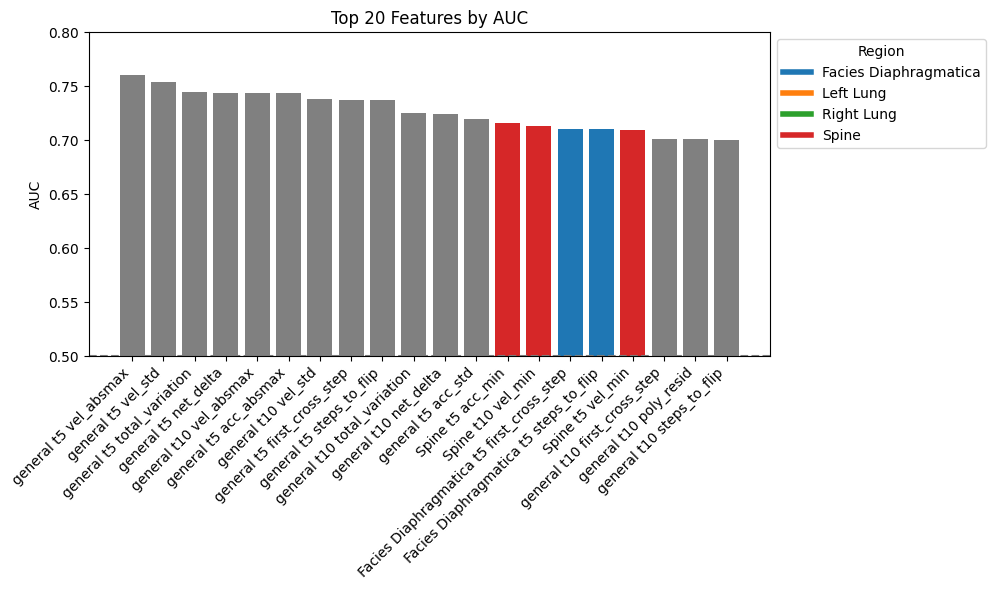

In [ ]:
# Plot 10 highest AUC features, one subplot per (region, t_start) cell, with the feature on the x-axis and the AUC on the y-axis. Use a horizontal line at 0.5 to indicate chance level.
top_feats = screen.nlargest(20, 'auc')
top_feats

# Plot the top 10 features by AUC, one subplot per (region, t_start) cell
# Use a horizontal line at 0.5 to indicate chance level.
# x TICK SHOULD BE REGION + T_START + FEATURE NAME, y = AUC

# Colour Map: Use one colour per region
colors = {r: c for r, c in zip(config['regions'], plt.cm.tab10.colors)}
fig, ax = plt.subplots(figsize=(10, 6))
x_labels = [f"{row['region']} t{row['t_start']} {row['feature']}" for _, row in top_feats.iterrows()]
ax.bar(
    x_labels,
    top_feats['auc'],
    color=[colors.get(row['region'], 'gray') for _, row in top_feats.iterrows()]
)
ax.axhline(0.5, color='gray', linestyle='--', label='Chance level (0.5)')
ax.set_ylabel('AUC')
ax.set_title('Top 20 Features by AUC')
ax.set_ylim(0.5, 0.8)
ax.set_xticklabels(x_labels, rotation=45, ha='right')
# Legend explaining the colours for each region, inside the plot area
handles = [plt.Line2D([0], [0], color=colors[r], lw=4) for r in config['regions']]
# pUT IT INSIDE THE PLOT AREA, NOT OUTSIDE
ax.legend(handles, config['regions'], title='Region', loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

/tmp/ipykernel_3121353/4036087716.py:22: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(x_labels, rotation=45, ha='right')


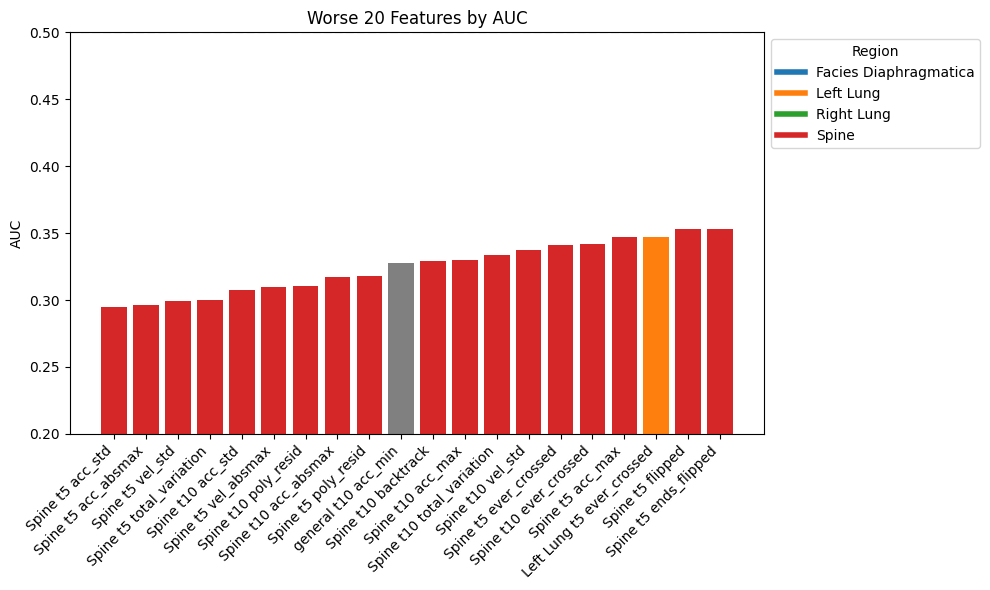

In [ ]:
# Plot 10 lowest AUC features, one subplot per (region, t_start) cell, with the feature on the x-axis and the AUC on the y-axis. Use a horizontal line at 0.5 to indicate chance level.
top_feats = screen.nsmallest(20, 'auc')
top_feats

# Plot the top 10 features by AUC, one subplot per (region, t_start) cell
# Use a horizontal line at 0.5 to indicate chance level.
# x TICK SHOULD BE REGION + T_START + FEATURE NAME, y = AUC

# Colour Map: Use one colour per region
colors = {r: c for r, c in zip(config['regions'], plt.cm.tab10.colors)}
fig, ax = plt.subplots(figsize=(10, 6))
x_labels = [f"{row['region']} t{row['t_start']} {row['feature']}" for _, row in top_feats.iterrows()]
ax.bar(
    x_labels,
    top_feats['auc'],
    color=[colors.get(row['region'], 'gray') for _, row in top_feats.iterrows()]
)
ax.axhline(0.5, color='gray', linestyle='--', label='Chance level (0.5)')
ax.set_ylabel('AUC')
ax.set_title('Worse 20 Features by AUC')
ax.set_ylim(0.2, 0.5)
ax.set_xticklabels(x_labels, rotation=45, ha='right')
# Legend explaining the colours for each region, inside the plot area
handles = [plt.Line2D([0], [0], color=colors[r], lw=4) for r in config['regions']]
# pUT IT INSIDE THE PLOT AREA, NOT OUTSIDE
ax.legend(handles, config['regions'], title='Region', loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

In [ ]:


ok['correct'] = ok['quadrant'].isin(['tp', 'tn']).map({True: 'correct', False: 'incorrect'})

CORR_ORDER = ['correct', 'incorrect']
CORR_PALETTE = {'correct': '#2e7d32', 'incorrect': '#c62828'}

def plot_quadrant_box(df, feature, region, t_start, ax=None, verbose=True):
    """
    Boxplot of `feature` by quadrant for one (region, t_start) slice.

    df      : the long dataframe (e.g. `ok`)
    ax      : optional matplotlib axis; if None a new figure is made
    verbose : print per-quadrant means
    """
    sub = df[(df['region'] == region) & (df['t_start'] == t_start)]

    if verbose:
        for c in ['correct', 'incorrect']:
            m = sub[sub['correct'] == c][feature].mean()
            print(f"[{region} t{t_start}] mean {feature} for {c}: {m:.4f}")

    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 6))

    sns.boxplot(data=sub, x='correct', y=feature,
                order=CORR_ORDER,
                palette=[CORR_PALETTE[c] for c in CORR_ORDER],
                ax=ax)
    ax.set_title(f"{feature} | {region} | t{t_start}")
    ax.set_xlabel('Correctness')
    ax.set_ylabel(feature)
    return ax


def plot_quadrant_grid(df, combos, ncols=3, figsize_per=(5, 4.5), verbose=False):
    """
    Grid of quadrant boxplots, one panel per (feature, t_start, region) triple.
    Wraps to `ncols` columns instead of one long row.
    """
    n = len(combos)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(figsize_per[0] * ncols,
                                      figsize_per[1] * nrows))
    axes = np.atleast_1d(axes).ravel()

    for ax, (feat, t, reg) in zip(axes, combos):
        plot_quadrant_box(df, feat, reg, t, ax=ax, verbose=verbose)

    # blank out unused panels
    for ax in axes[n:]:
        ax.axis('off')

    plt.tight_layout()
    return fig, axes

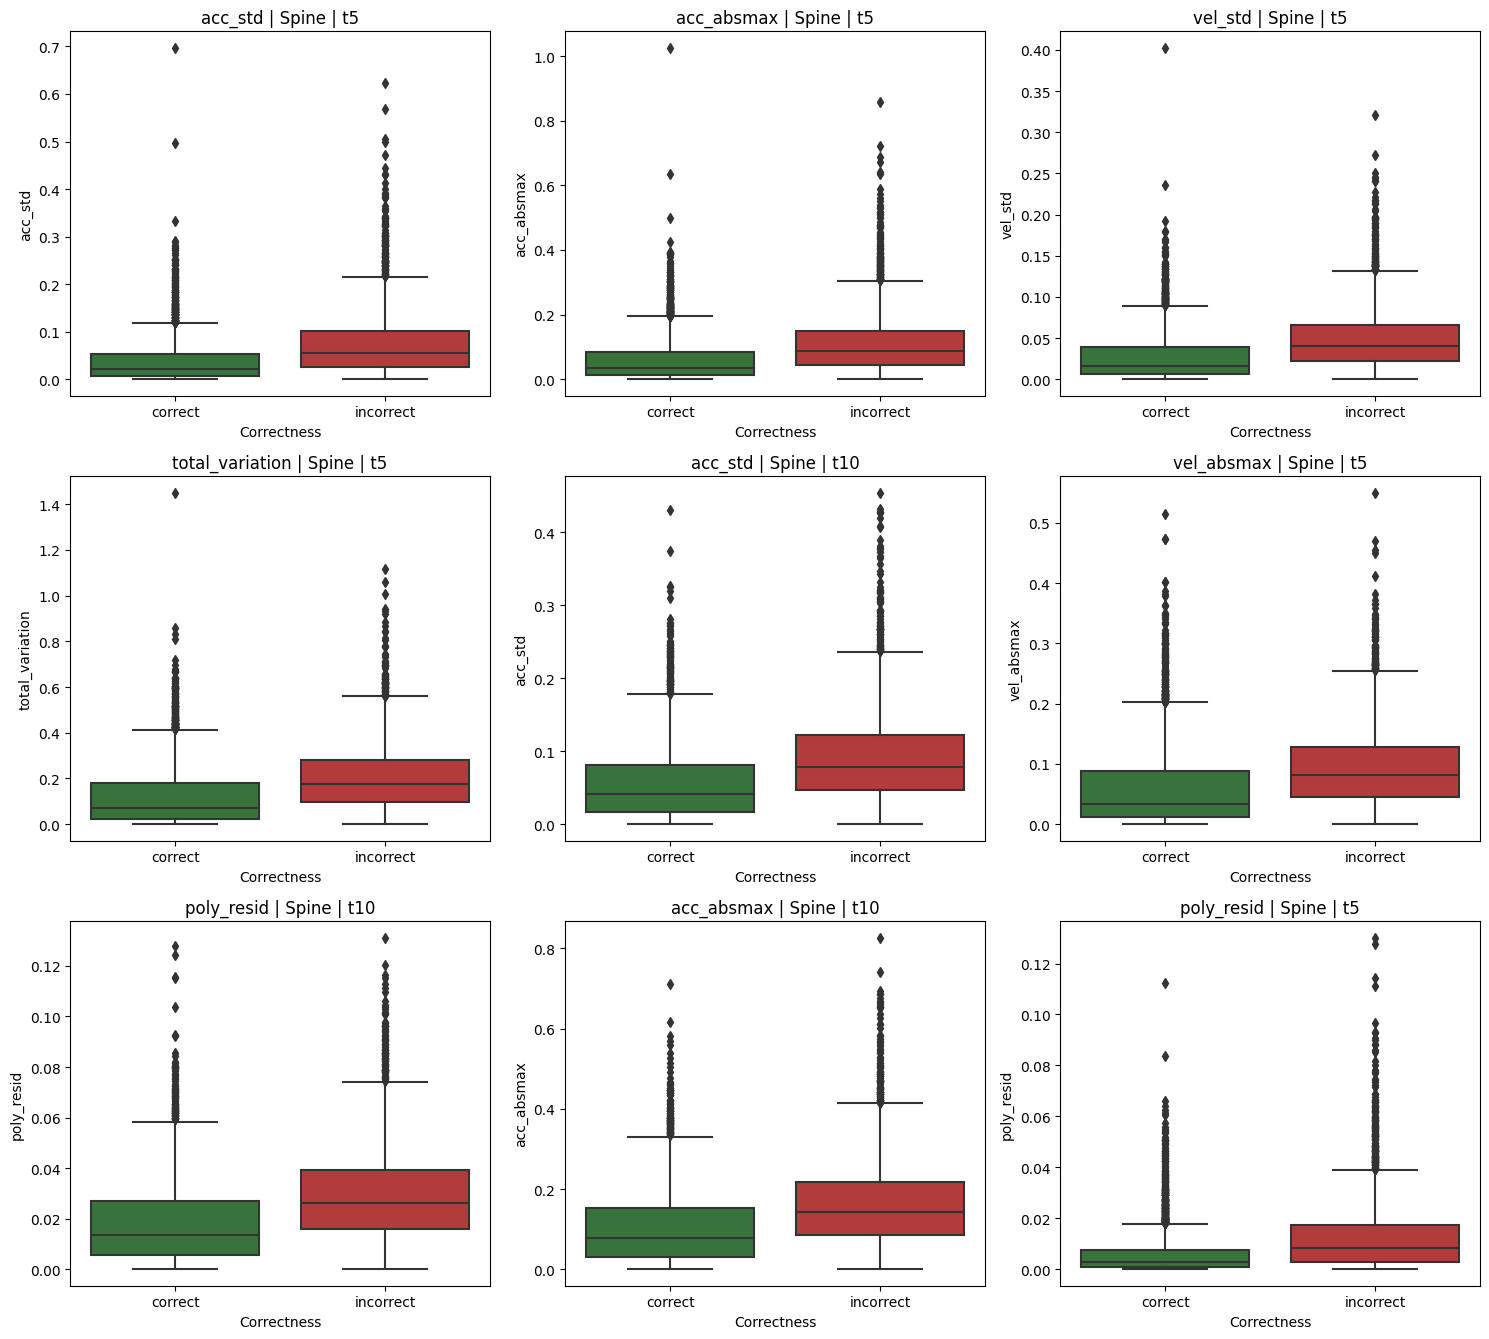

In [ ]:
combos = [(r['feature'], r['t_start'], r['region']) for _, r in top_feats.head(9).iterrows()]
# Average across t_steps so we compare only the features, not the t_start. So we take the mean AUC across t_start for each feature and region, and then take the top 9 features by mean AUC.
plot_quadrant_grid(ok, combos, ncols=3)
plt.show()

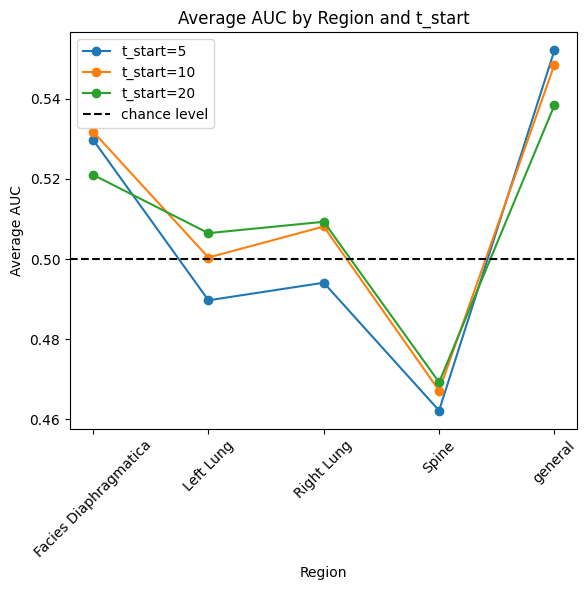

In [ ]:

# Average AUC by region and t_start
avg_auc = screen.groupby(['region', 't_start'])['auc'].mean().reset_index()
avg_auc

# Plot average AUC by region and t_start, with region on the x-axis and average AUC on the y-axis, and a separate line for each t_start. Use a horizontal line at 0.5 to indicate chance level.
plt.figure(figsize=(6, 6))
for t_start, group in avg_auc.groupby('t_start'):
    plt.plot(group['region'], group['auc'], marker='o', label=f't_start={t_start}')
plt.axhline(0.5, color='k', linestyle='--', label='chance level')
plt.title('Average AUC by Region and t_start')
plt.xlabel('Region')
plt.ylabel('Average AUC')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()  
plt.show()


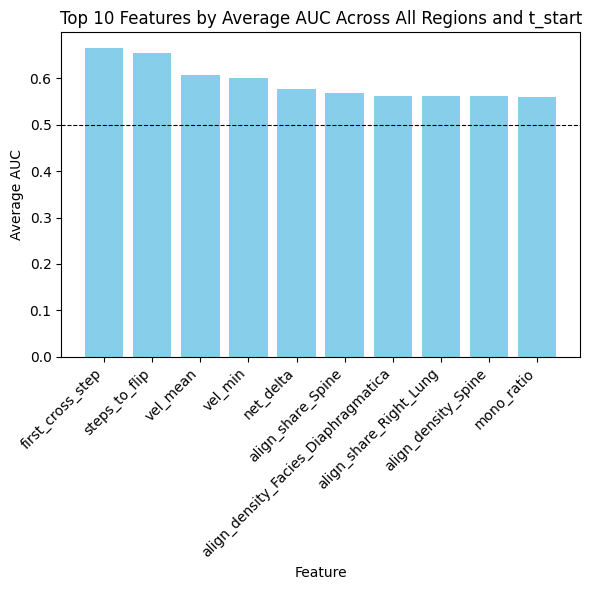

In [ ]:
# What are the features across all regions and t_start that have the highest average AUC? Let's find the top 10 features by average AUC across all regions and t_start.
avg_auc_features = screen.groupby('feature')['auc'].mean().reset_index()
top10_avg_auc_features = avg_auc_features.nlargest(10, 'auc')
top10_avg_auc_features

# Plot their average AUC across all regions and t_start
plt.figure(figsize=(6, 6))
plt.bar(top10_avg_auc_features['feature'], top10_avg_auc_features['auc'], color='skyblue')
plt.axhline(0.5, ls='--', c='k', lw=0.8)
plt.xticks(rotation=45, ha='right')
plt.xlabel('Feature')
plt.ylabel('Average AUC')
plt.title('Top 10 Features by Average AUC Across All Regions and t_start')
plt.tight_layout()
plt.show()

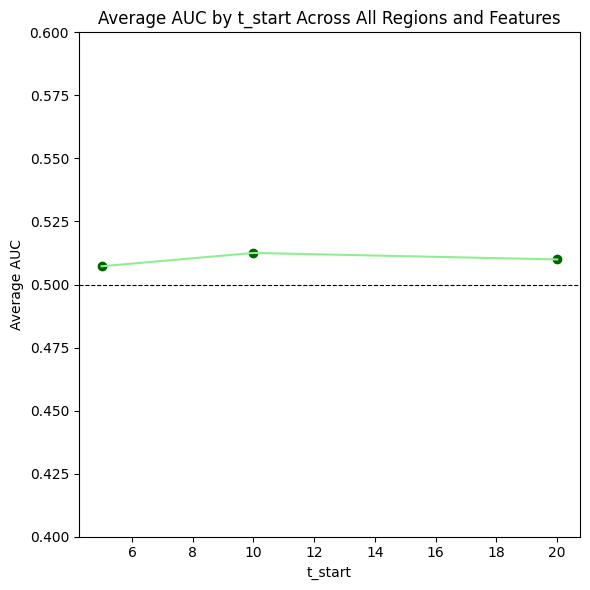

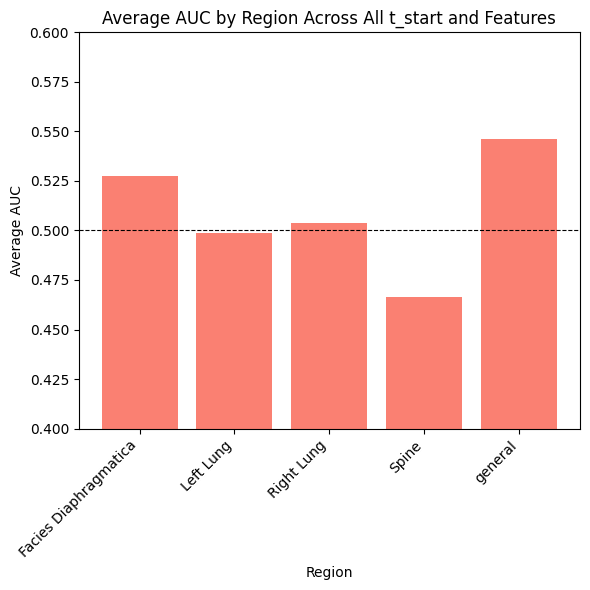

In [ ]:
# Plot average t_Step auc across all regions and features, then plot average region auc across all t_start and features
# Average AUC by t_start
avg_auc_t_start = screen.groupby('t_start')['auc'].mean().reset_index()
plt.figure(figsize=(6, 6))
plt.plot(avg_auc_t_start['t_start'], avg_auc_t_start['auc'], color='lightgreen')
# Add dots at each t_start value
plt.scatter(avg_auc_t_start['t_start'], avg_auc_t_start['auc'], color='darkgreen')
# Horizontal line at 0.5
plt.axhline(0.5, ls='--', c='k', lw=0.8)
plt.ylim(0.4, 0.6)
plt.xlabel('t_start')
plt.ylabel('Average AUC')
plt.title('Average AUC by t_start Across All Regions and Features')
plt.tight_layout()
plt.show()

# Average AUC by region
avg_auc_region = screen.groupby('region')['auc'].mean().reset_index()
plt.figure(figsize=(6, 6))
plt.bar(avg_auc_region['region'], avg_auc_region['auc'], color='salmon')
plt.axhline(0.5, ls='--', c='k', lw=0.8)

plt.xticks(rotation=45, ha='right')
plt.ylim(0.4, 0.6)
plt.xlabel('Region')
plt.ylabel('Average AUC')
plt.title('Average AUC by Region Across All t_start and Features')
plt.tight_layout()
plt.show()

In [ ]:
FEATS

['orig_prob',
 'cf_prob',
 'flipped',
 'traj_start',
 'traj_end',
 'n_steps',
 'first_cross_step',
 'ever_crossed',
 'steps_to_flip',
 'ends_flipped',
 'n_crossings',
 'mono_ratio',
 'backtrack',
 'n_reversals',
 'reversal_rate',
 'tv_ratio',
 'spearman',
 'net_delta',
 'total_variation',
 'p0_level',
 'p1_slope',
 'p2_curvature',
 'p3_sshape',
 'poly_resid',
 'vel_mean',
 'vel_max',
 'vel_min',
 'vel_std',
 'vel_absmax',
 'vel_argmax_pos',
 'acc_mean',
 'acc_max',
 'acc_min',
 'acc_std',
 'acc_absmax',
 'acc_argmax_pos',
 'l1',
 'l2',
 'peak_pixel',
 'mean_pixel_abs',
 'entropy',
 'ent_normalized_by_size',
 'area',
 'frac_frame',
 'align_share_Facies_Diaphragmatica',
 'align_density_Facies_Diaphragmatica',
 'align_share_Left_Lung',
 'align_density_Left_Lung',
 'align_share_Right_Lung',
 'align_density_Right_Lung',
 'align_share_Spine',
 'align_density_Spine']

In [ ]:
ID_COLS = {'path','cf_id','patient_id','region','quadrant','true','correct','mask_empty'}
IMG_LEVEL = []          # same for all 15 cells
CELL_FEATS = [c for c in FEATS if c not in IMG_LEVEL]

ok = cf_all[cf_all['mask_empty'] == 0]

# 15 cells x per-cell features -> wide, one row per image
wide = ok.pivot_table(index='path', columns=['region','t_start'],
                      values=CELL_FEATS, aggfunc='first')
wide.columns = [f"{f}__{r.replace(' ','_')}__t{t}" for f, r, t in wide.columns]

# image-level columns joined back on
meta = (ok.groupby('path')
          .agg(patient_id=('patient_id','first'), correct=('correct','first'),
               boundary_dist=('boundary_dist','first'), orig_prob=('orig_prob','first'),
               quadrant=('quadrant','first')))
X_all = meta.join(wide)
print(X_all.shape, '| images:', len(X_all), '| patients:', X_all.patient_id.nunique())


X_all

(5431, 689) | images: 5431 | patients: 4397


,patient_id,correct,boundary_dist,orig_prob,quadrant,acc_absmax__Facies_Diaphragmatica__t5,acc_absmax__Facies_Diaphragmatica__t10,acc_absmax__Facies_Diaphragmatica__t20,acc_absmax__Left_Lung__t5,acc_absmax__Left_Lung__t10,...,vel_std__Left_Lung__t20,vel_std__Right_Lung__t5,vel_std__Right_Lung__t10,vel_std__Right_Lung__t20,vel_std__Spine__t5,vel_std__Spine__t10,vel_std__Spine__t20,vel_std__general__t5,vel_std__general__t10,vel_std__general__t20
path,,,,,,,,,,,,,,,,,,,,,
CheXpert-v1.0-small/train/patient00012/study2/view1_frontal.jpg,patient00012,1,0.501892,0.061508,tn,0.173528,0.170719,0.145019,0.039830,0.075293,...,0.071447,0.078322,0.049380,0.076817,0.022951,0.049144,0.072527,0.129648,0.066378,0.038343
CheXpert-v1.0-small/train/patient00039/study1/view1_frontal.jpg,patient00039,0,0.451423,0.111977,fn,0.378048,0.151161,0.442083,0.182928,0.221413,...,0.051618,0.060437,0.088977,0.053237,0.026048,0.063257,0.041659,0.231917,0.125904,0.081570
CheXpert-v1.0-small/train/patient00065/study2/view1_frontal.jpg,patient00065,1,0.552834,0.010566,tn,0.123867,0.117687,0.149505,0.013514,0.493186,...,0.061893,0.026087,0.097730,0.057908,0.001441,0.003458,0.025199,0.200814,0.058413,0.033330
CheXpert-v1.0-small/train/patient00070/study1/view1_frontal.jpg,patient00070,1,0.548339,0.015061,tn,0.205005,0.125036,0.147922,0.028218,0.368903,...,0.069387,0.013850,0.100316,0.074422,0.003375,0.032765,0.063810,0.078955,0.035331,0.036189
CheXpert-v1.0-small/train/patient00087/study3/view2_frontal.jpg,patient00087,0,0.432567,0.130833,fn,0.138455,0.222386,0.100418,0.033012,0.137205,...,0.055704,0.047034,0.098152,0.040512,0.040181,0.070156,0.085314,0.016341,0.110858,0.043903
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
CheXpert-v1.0-small/train/patient47271/study1/view1_frontal.jpg,patient47271,0,0.224394,0.339006,fn,0.100239,0.146708,0.134956,0.238524,0.130848,...,0.047195,0.036122,0.024948,0.035252,0.015504,0.044530,0.046343,0.027261,0.024668,0.010766
CheXpert-v1.0-small/train/patient47272/study1/view1_frontal.jpg,patient47272,0,0.468130,0.095270,fn,0.014705,0.234543,0.329024,0.043191,0.222560,...,0.062008,0.073297,0.040144,0.054554,0.131417,0.126661,0.124081,0.004647,0.029244,0.031571
CheXpert-v1.0-small/train/patient47278/study1/view1_frontal.jpg,patient47278,1,0.531509,0.031891,tn,0.479702,0.186228,0.204330,0.564280,0.221232,...,0.043565,0.015453,0.054387,0.082046,0.015256,0.082637,0.110499,0.169174,0.107841,0.032058


In [ ]:
# Print what goes as input to the models    
print("Input to the models (X_all):")
for col in X_all.columns:
    print(col)

Input to the models (X_all):
patient_id
correct
boundary_dist
orig_prob
quadrant
acc_absmax__Facies_Diaphragmatica__t5
acc_absmax__Facies_Diaphragmatica__t10
acc_absmax__Facies_Diaphragmatica__t20
acc_absmax__Left_Lung__t5
acc_absmax__Left_Lung__t10
acc_absmax__Left_Lung__t20
acc_absmax__Right_Lung__t5
acc_absmax__Right_Lung__t10
acc_absmax__Right_Lung__t20
acc_absmax__Spine__t5
acc_absmax__Spine__t10
acc_absmax__Spine__t20
acc_absmax__general__t5
acc_absmax__general__t10
acc_absmax__general__t20
acc_argmax_pos__Facies_Diaphragmatica__t5
acc_argmax_pos__Facies_Diaphragmatica__t10
acc_argmax_pos__Facies_Diaphragmatica__t20
acc_argmax_pos__Left_Lung__t5
acc_argmax_pos__Left_Lung__t10
acc_argmax_pos__Left_Lung__t20
acc_argmax_pos__Right_Lung__t5
acc_argmax_pos__Right_Lung__t10
acc_argmax_pos__Right_Lung__t20
acc_argmax_pos__Spine__t5
acc_argmax_pos__Spine__t10
acc_argmax_pos__Spine__t20
acc_argmax_pos__general__t5
acc_argmax_pos__general__t10
acc_argmax_pos__general__t20
acc_max__Facies_D

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from tqdm.auto import tqdm

y      = X_all['correct'].values
groups = X_all['patient_id'].values
fp_cols = [c for c in X_all.columns if '__' in c]      # the 15-cell fingerprint

SETS = {
    'probability only': ['orig_prob'],
    'fingerprint only'  : fp_cols,
    'both'              : ['orig_prob'] + fp_cols,
}

N_SPLITS = 5
cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)

results = {}
pbar = tqdm(total=len(SETS) * N_SPLITS, desc="CV")
for name, cols in SETS.items():
    X = X_all[cols].values
    aucs = []
    for tr, te in cv.split(X, y, groups):
        m = HistGradientBoostingClassifier(max_iter=1000, random_state=0).fit(X[tr], y[tr])
        aucs.append(roc_auc_score(y[te], m.predict_proba(X[te])[:, 1]))
        pbar.update(1)
        pbar.set_postfix_str(f"{name}: {np.mean(aucs):.4f}")
    results[name] = aucs
pbar.close()

for name, aucs in results.items():
    print(f"{name:<20} AUC {np.mean(aucs):.4f} ± {np.std(aucs):.4f}   {np.round(aucs, 4)}")



CV:   0%|          | 0/15 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
# Instead of running the 15 cell ablation load results from: /zhome/d0/a/221493/thesis/results/diverse_cf/cell_ablation_aucs.csv
ablation_results_path = '/zhome/d0/a/221493/thesis/results/diverse_cf/cell_ablation_aucs.csv'
ablation_results = pd.read_csv(ablation_results_path)
ablation_results

# sort by decreasing mean AUC
ablation_results = ablation_results.sort_values('auc_mean', ascending=False).reset_index(drop=True)

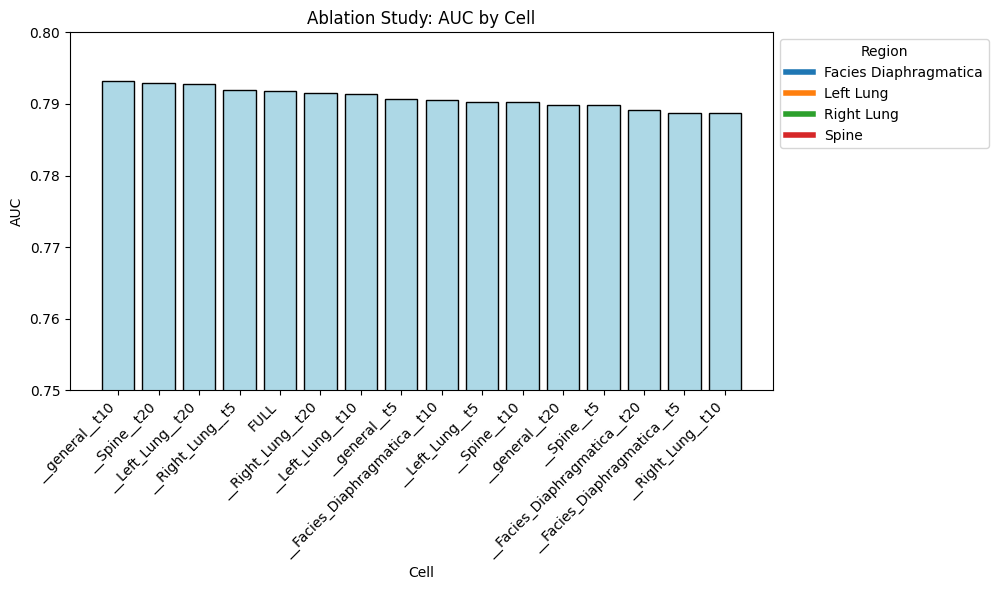

In [64]:
# Plot the ablation results as a bar plot, with the cell on the x-axis and the AUC on the y-axis. Use a horizontal line at 0.5 to indicate chance level. Color the bars by region.
plt.figure(figsize=(10, 6))
# Create a color map for the regions
# Create a bar plot
plt.bar(ablation_results['cell'], ablation_results['auc_mean'], color='lightblue', edgecolor='k')
plt.axhline(0.5, color='k', linestyle='--', label='Chance level (0.5)')
plt.xticks(rotation=45, ha='right')
plt.xlabel('Cell')
plt.ylabel('AUC')
plt.title('Ablation Study: AUC by Cell')
# Create a legend for the regions
plt.legend(handles, config['regions'], title='Region', loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
# set ylimits to 0.5 to 1
plt.ylim(0.75,0.8)
plt.show()